In [2]:
!pip install -q kaggle ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 81.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 7.2 MB/s eta 0:00:00


In [3]:
from getpass import getpass

KAGGLE_API_TOKEN = getpass("Enter your Kaggle API token: ")

Enter your Kaggle API token: ··········


In [4]:
import os

os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

In [5]:
!kaggle datasets list -s garbage-detection

ref                                                            title                                                 size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-------------------------------------------------------------  ----------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
fatemehboloori/trash-type-detection                            garbage type detection                            42813821  2023-10-16 07:00:15.553000           1071         25  0.6875           
viswaprakash1990/garbage-detection                             Garbage Detection – 6 Waste Categories           199963613  2025-05-20 17:32:59.337000           3536         28  1                
sumn2u/garbage-classification-v2                               Garbage Dataset                                 1147864104  2026-02-23 00:36:31.490000          28069        192  1                
vencerlanz09/plastic-pape

In [6]:
!kaggle datasets download -d viswaprakash1990/garbage-detection -p /content

Dataset URL: https://www.kaggle.com/datasets/viswaprakash1990/garbage-detection
License(s): Attribution 4.0 International (CC BY 4.0)
100% 191M/191M [00:18<00:00, 10.5MB/s]



In [7]:
!ls -lh /content

total 191M
-rw-r--r-- 1 root root 191M May 20  2025 garbage-detection.zip
drwxr-xr-x 1 root root 4.0K Aug 24 13:28 sample_data


In [8]:
import zipfile
import os

zip_path = "/content/garbage-detection.zip"
extract_path = "/content/garbage_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [9]:
for root, dirs, files in os.walk("/content/garbage_dataset"):
    level = root.replace("/content/garbage_dataset", "").count(os.sep)

    if level <= 3:
        print(root)

/content/garbage_dataset
/content/garbage_dataset/GARBAGE CLASSIFICATION
/content/garbage_dataset/GARBAGE CLASSIFICATION/train
/content/garbage_dataset/GARBAGE CLASSIFICATION/train/labels
/content/garbage_dataset/GARBAGE CLASSIFICATION/train/images
/content/garbage_dataset/GARBAGE CLASSIFICATION/valid
/content/garbage_dataset/GARBAGE CLASSIFICATION/valid/labels
/content/garbage_dataset/GARBAGE CLASSIFICATION/valid/images
/content/garbage_dataset/GARBAGE CLASSIFICATION/test
/content/garbage_dataset/GARBAGE CLASSIFICATION/test/labels
/content/garbage_dataset/GARBAGE CLASSIFICATION/test/images


In [10]:
for root, dirs, files in os.walk("/content/garbage_dataset"):
    if "data.yaml" in files:
        print("YAML:", os.path.join(root, "data.yaml"))

YAML: /content/garbage_dataset/GARBAGE CLASSIFICATION/data.yaml


In [11]:
yaml_path = "/content/garbage_dataset/GARBAGE CLASSIFICATION/data.yaml"

with open(yaml_path, "r") as f:
    print(f.read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 6
names: ['BIODEGRADABLE', 'CARDBOARD', 'GLASS', 'METAL', 'PAPER', 'PLASTIC']

roboflow:
  workspace: material-identification
  project: garbage-classification-3
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/material-identification/garbage-classification-3/dataset/2


In [12]:
import os

dataset_root = "/content/garbage_dataset/GARBAGE CLASSIFICATION"

for root, dirs, files in os.walk(dataset_root):
    level = root.replace(dataset_root, "").count(os.sep)

    if level <= 2:
        print(root)

/content/garbage_dataset/GARBAGE CLASSIFICATION
/content/garbage_dataset/GARBAGE CLASSIFICATION/train
/content/garbage_dataset/GARBAGE CLASSIFICATION/train/labels
/content/garbage_dataset/GARBAGE CLASSIFICATION/train/images
/content/garbage_dataset/GARBAGE CLASSIFICATION/valid
/content/garbage_dataset/GARBAGE CLASSIFICATION/valid/labels
/content/garbage_dataset/GARBAGE CLASSIFICATION/valid/images
/content/garbage_dataset/GARBAGE CLASSIFICATION/test
/content/garbage_dataset/GARBAGE CLASSIFICATION/test/labels
/content/garbage_dataset/GARBAGE CLASSIFICATION/test/images


In [13]:
train_images = f"{dataset_root}/train/images"
train_labels = f"{dataset_root}/train/labels"

val_images = f"{dataset_root}/valid/images"
val_labels = f"{dataset_root}/valid/labels"

test_images = f"{dataset_root}/test/images"
test_labels = f"{dataset_root}/test/labels"

print("TRAIN")
print("Images:", len(os.listdir(train_images)))
print("Labels:", len(os.listdir(train_labels)))

print("\nVALIDATION")
print("Images:", len(os.listdir(val_images)))
print("Labels:", len(os.listdir(val_labels)))

print("\nTEST")
print("Images:", len(os.listdir(test_images)))
print("Labels:", len(os.listdir(test_labels)))

TRAIN
Images: 7324
Labels: 7324

VALIDATION
Images: 2098
Labels: 2098

TEST
Images: 1042
Labels: 1042


In [14]:
import yaml

data = {
    "train": f"{dataset_root}/train/images",
    "val": f"{dataset_root}/valid/images",
    "test": f"{dataset_root}/test/images",

    "nc": 6,

    "names": [
        "BIODEGRADABLE",
        "CARDBOARD",
        "GLASS",
        "METAL",
        "PAPER",
        "PLASTIC"
    ]
}

custom_yaml = "/content/waste_data.yaml"

with open(custom_yaml, "w") as f:
    yaml.dump(data, f, sort_keys=False)

print("Created:", custom_yaml)

Created: /content/waste_data.yaml


In [15]:
!cat /content/waste_data.yaml

train: /content/garbage_dataset/GARBAGE CLASSIFICATION/train/images
val: /content/garbage_dataset/GARBAGE CLASSIFICATION/valid/images
test: /content/garbage_dataset/GARBAGE CLASSIFICATION/test/images
nc: 6
names:
- BIODEGRADABLE
- CARDBOARD
- GLASS
- METAL
- PAPER
- PLASTIC


In [16]:
import os

label_files = os.listdir(train_labels)

print("First 5 label files:")

for file in label_files[:5]:
    path = os.path.join(train_labels, file)

    print("\n", file)

    with open(path, "r") as f:
        print(f.read()[:500])

First 5 label files:

 metal568_jpg.rf.580c1f2a055a6cc396dc6bcaf99a36ae.txt
3 0.4411057692307692 0.5240384615384616 0.47596153846153844 0.35336538461538464

 biodegradable1808_jpeg.rf.f4625e06ce688b01c4d66ea244d144c4.txt
0 0.7548076923076923 0.05889423076923077 0.1971153846153846 0.11057692307692307
0 0.6009615384615384 0.04567307692307692 0.12980769230769232 0.08413461538461539
0 0.484375 0.03245192307692308 0.10576923076923077 0.057692307692307696
0 0.48197115384615385 0.10096153846153846 0.17307692307692307 0.11057692307692307
0 0.39302884615384615 0.09975961538461539 0.0985576923076923 0.10576923076923077
0 0.3076923076923077 0.1502403846153846 0.07211538461538461 0.09615384615384616
0 0.31971153846153844 0.

 glass1966_jpg.rf.41bf0ea1594338340677ad52beba6d9c.txt
2 0.6009615384615384 0.6141826923076923 0.7932692307692307 0.6466346153846154

 biodegradable228_jpg.rf.966c7191c62a974c11ffbb5d4eada830.txt
0 0.6286057692307693 0.6009615384615384 0.2692307692307692 0.42788461538461536
0 

In [17]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.


In [18]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Ultralytics version: 8.4.136


In [19]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [20]:
model = YOLO("yolov8n.pt")

In [21]:
results = model.train(
    data="/content/waste_data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    patience=10,
    project="/content/waste_detection",
    name="waste_yolo"
)

Ultralytics 8.4.136 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/waste_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=waste_yolo, nbs=64, nms=False, opset=N

In [22]:
import os

weights_path = "/content/waste_detection/waste_yolo/weights"

print(os.listdir(weights_path))

['best.pt', 'last.pt']


In [24]:
best_model = YOLO(
    "/content/waste_detection/waste_yolo/weights/best.pt"
)

In [25]:
metrics = best_model.val(
    data="/content/waste_data.yaml"
)

Ultralytics 8.4.136 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 827.0±545.8 MB/s, size: 19.4 KB)
val: Scanning /content/garbage_dataset/GARBAGE CLASSIFICATION/valid/labels.cache... 2098 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2098/2098 733.3Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 311 objects (val=311), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=311 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 132/132 5.4it/s 24.3s
                   all       2098      18916       0.59      0.436      0.512      0.347
         BIODEGRADABLE        676      13637      0.844    

In [26]:
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

mAP50: 0.5115742576400798
mAP50-95: 0.34707843127743304


In [27]:
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Precision: 0.5898581704224327
Recall: 0.43619935494801715


In [28]:
test_results = best_model.predict(
    source=test_images,
    conf=0.5,
    save=True
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1042 /content/garbage_dataset/GARBAGE CLASSIFICATION/test/images/metal1000_jpg.rf.f972491130c59d3bff7e97b22e8e2980.jpg: 640x640 (no detections), 7.9ms
image 2/1042 /content/garbage_dataset/GARBAGE CLASSIFICATION/test/images/metal1005_jpg.rf.d736ab336e8fa92ce57727666e624259.jpg: 640x640 1 GLASS, 8.9ms
image 3/1042 /content/garbage_dataset/GARBAGE CLASSIFICATION/test/images/metal100_jpg.rf.8605f3d87c15f6f37575fa2907d5bc6c.jpg: 640x640 2 METALs, 8.2m

In [29]:
import glob

prediction_folders = glob.glob("/content/runs/detect/*")

print(prediction_folders)

['/content/runs/detect/predict', '/content/runs/detect/val']


Number of prediction images: 1042


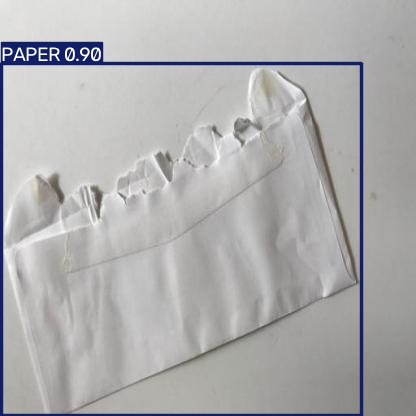

In [30]:
from IPython.display import Image, display
import glob
import os

images = glob.glob("/content/runs/detect/predict/*.jpg")

print("Number of prediction images:", len(images))

if len(images) > 0:
    display(Image(filename=images[0]))

In [31]:
category_mapping = {
    "BIODEGRADABLE": "BIODEGRADABLE",
    "CARDBOARD": "NON-BIODEGRADABLE",
    "GLASS": "NON-BIODEGRADABLE",
    "METAL": "NON-BIODEGRADABLE",
    "PAPER": "NON-BIODEGRADABLE",
    "PLASTIC": "NON-BIODEGRADABLE"
}

In [39]:
from google.colab import files

uploaded = files.upload()

Saving glass.avif to glass.avif


In [40]:
image_name = list(uploaded.keys())[0]

results = best_model.predict(
    source=image_name,
    conf=0.2
)


image 1/1 /content/glass.avif: 640x448 1 GLASS, 43.7ms
Speed: 2.6ms preprocess, 43.7ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 448)


In [41]:
for result in results:

    for box in result.boxes:

        class_id = int(box.cls[0])

        confidence = float(box.conf[0])

        class_name = best_model.names[class_id]

        category = category_mapping[class_name]

        print("Detected object :", class_name)
        print("Final category  :", category)
        print("Confidence      :", f"{confidence:.2%}")
        print("-" * 40)

Detected object : GLASS
Final category  : NON-BIODEGRADABLE
Confidence      : 93.33%
----------------------------------------
